# 06 Model Interpretation

Interpret model drivers and translate analytical results into stakeholder insights.

Add the executed analysis, outputs, and findings for this stage below.

TELCO CUSTOMER CHURN CLASSIFICATION
STAGE 6: MODEL INTERPRETATION

Dataset and evaluation results loaded!

[1] SELECTING BEST MODEL
Selected model: Logistic Regression

[2] CALCULATING FEATURE IMPORTANCE

Top 10 Important Features:
         Feature  Importance      Std
          tenure    0.195386 0.018120
 InternetService    0.111788 0.021229
        Contract    0.111738 0.011488
  OnlineSecurity    0.031268 0.009651
     TechSupport    0.030313 0.006341
   PaymentMethod    0.019230 0.005526
    OnlineBackup    0.017469 0.006548
PaperlessBilling    0.016415 0.006574
 StreamingMovies    0.013963 0.007629
   MultipleLines    0.009875 0.006994

[3] FEATURE IMPORTANCE VISUALIZATION


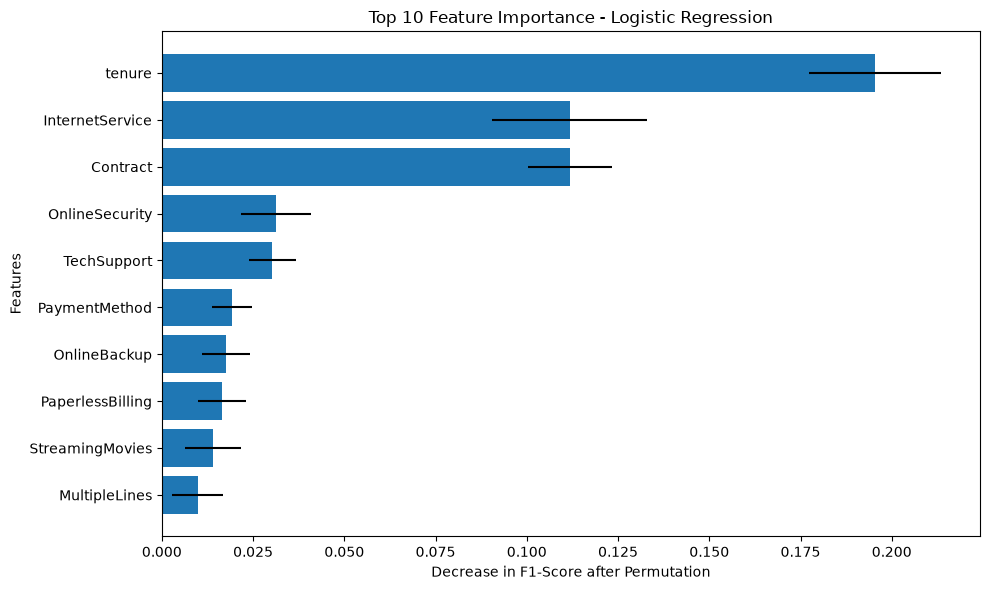


[4] BUSINESS INSIGHTS

Top 5 features influencing model performance:
- tenure: 0.1954
- InternetService: 0.1118
- Contract: 0.1117
- OnlineSecurity: 0.0313
- TechSupport: 0.0303

Interpretation:
Features with higher importance have a greater influence on the model's predictive performance.

Feature importance results saved!

STAGE 6 COMPLETED SUCCESSFULLY!


In [1]:

# ============================================================
# TELCO CUSTOMER CHURN CLASSIFICATION
# STAGE 6: MODEL INTERPRETATION
# ============================================================

import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from sklearn.inspection import permutation_importance

print("=" * 60)
print("TELCO CUSTOMER CHURN CLASSIFICATION")
print("STAGE 6: MODEL INTERPRETATION")
print("=" * 60)

# ------------------------------------------------------------
# 1. LOAD DATASET AND EVALUATION RESULTS
# ------------------------------------------------------------

df = pd.read_csv("../data/cleaned_telco_churn.csv")

results_df = pd.read_csv(
    "../data/model_evaluation_results.csv"
)

print("\nDataset and evaluation results loaded!")

# ------------------------------------------------------------
# 2. PREPARE FEATURES AND TARGET
# ------------------------------------------------------------

X = df.drop(columns=["Churn", "customerID"])
y = df["Churn"]

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# ------------------------------------------------------------
# 3. SELECT BEST MODEL
# ------------------------------------------------------------

print("\n[1] SELECTING BEST MODEL")

best_model_name = results_df.loc[
    results_df["F1-Score"].idxmax(),
    "Model"
]

model_files = {
    "Logistic Regression": "logistic_regression.pkl",
    "Decision Tree": "decision_tree.pkl",
    "Random Forest": "random_forest.pkl"
}

best_model = joblib.load(
    Path("../models") / model_files[best_model_name]
)

print(f"Selected model: {best_model_name}")

# ------------------------------------------------------------
# 4. PERMUTATION FEATURE IMPORTANCE
# ------------------------------------------------------------

print("\n[2] CALCULATING FEATURE IMPORTANCE")

importance_result = permutation_importance(
    best_model,
    X_test,
    y_test,
    n_repeats=10,
    random_state=42,
    scoring="f1",
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": importance_result.importances_mean,
    "Std": importance_result.importances_std
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print("\nTop 10 Important Features:")
print(importance_df.head(10).to_string(index=False))

# ------------------------------------------------------------
# 5. VISUALIZE FEATURE IMPORTANCE
# ------------------------------------------------------------

print("\n[3] FEATURE IMPORTANCE VISUALIZATION")

top_features = importance_df.head(10).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"],
    top_features["Importance"],
    xerr=top_features["Std"]
)

plt.title(
    f"Top 10 Feature Importance - {best_model_name}"
)

plt.xlabel("Decrease in F1-Score after Permutation")
plt.ylabel("Features")
plt.tight_layout()

image_dir = Path("../images")
image_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    image_dir / "08_feature_importance.png"
)

plt.show()

# ------------------------------------------------------------
# 6. GENERATE BUSINESS INSIGHTS
# ------------------------------------------------------------

print("\n[4] BUSINESS INSIGHTS")

print("\nTop 5 features influencing model performance:")

for index, row in importance_df.head(5).iterrows():
    print(
        f"- {row['Feature']}: "
        f"{row['Importance']:.4f}"
    )

print("\nInterpretation:")
print(
    "Features with higher importance have a greater "
    "influence on the model's predictive performance."
)

# ------------------------------------------------------------
# 7. SAVE FEATURE IMPORTANCE
# ------------------------------------------------------------

importance_df.to_csv(
    "../data/feature_importance_results.csv",
    index=False
)

print("\nFeature importance results saved!")

print("\n" + "=" * 60)
print("STAGE 6 COMPLETED SUCCESSFULLY!")
print("=" * 60)

